# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola, Juan! ¿Cómo va?<br><br>
Un gusto conocerte, seré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones! Tu análisis ejecutivo es de muy buen nivel: cuantificas cada problema de datos, das el tamaño y el consumo de cada segmento, concluyes con datos que la edad no diferencia el comportamiento y propones recomendaciones concretas para cada nivel de uso. También destaco el <i>named aggregation</i>, el <code>merge</code> con <code>how='left'</code> y el cruce edad × uso, que fue más allá de lo pedido.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración con <code>head()</code>, <code>shape</code> e <code>info()</code> completas.</li>
<li><b>Parte 2. Calidad de datos 🟡</b> — Nulos y sentinels bien identificados; revisa el diagnóstico de fechas (2022 y 2023 son años válidos).</li>
<li><b>Parte 3. Limpieza ❌</b> — Las filas de 2026 se <b>eliminaron</b> en lugar de marcar la fecha como nula. Revisa también la mediana de <code>age</code> y la salida de <code>city</code>.</li>
<li><b>Parte 4. Uso por usuario ✅</b> — <i>Named aggregation</i> y <code>merge</code> correctos.</li>
<li><b>Parte 5. Distribuciones y outliers ✅</b> — Histogramas, boxplots e IQR con porcentaje de outliers; decisiones bien argumentadas.</li>
<li><b>Parte 6. Segmentación ✅</b> — Segmentos correctos, countplots rotulados y un cruce edad × uso muy útil.</li>
<li><b>Parte 7. Insight ejecutivo ✅</b> — Completo, con cifras y recomendaciones accionables.</li>
<li><b>Parte 8. Publicación 🟡</b> — El link está en celdas de código.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto <b>aún no puede ser aceptado</b> por un único comentario rojo: la eliminación de los 40 registros de 2026, que deja la base en 3,960 clientes y cambia todos los porcentajes. Es un ajuste de una línea, y en cuanto lo corrijas ¡estará listo! Los comentarios amarillos son recomendaciones para pulir tu trabajo.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importimpoar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Librerías importadas en una sola celda al inicio. Corrige el error tipográfico del comentario ("importimpoar").
</div>

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code> sin <code>print()</code>.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [55]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Exploración estructural completa con <code>.shape</code> etiquetado y <code>.info()</code> en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [9]:
# cantidad de nulos para users


nulos_users=users.isna().sum()
proporcion_users=nulos_users/len(users)*100
print(nulos_users)
proporcion_users







user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64

In [10]:
# cantidad de nulos para usage
nulos_usage=usage.isna().sum()
proporcion_usage=nulos_usage/len(usage)*100
print(nulos_usage)
proporcion_usage


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo y proporción de nulos correctos en ambos datasets, expresados en porcentaje.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>df.isna().mean() * 100</code> da el mismo resultado en una sola línea, sin dividir entre <code>len()</code>.
</div>

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  USERS
   1- "city" con 11.72%
   2-"churn_date" con 88.35%
  USAGE
   3-"duration" con 55.19%
   4-"length" con 44.74%
- Indica qué harías: ¿imputar, eliminar, ignorar?
    "city" se ignoran porque el(la) usuari@ no proporciono su ciudad por tema de sensibiliad y afectara a los demas datos si se eliminan
    "churn_date" de igual manera se ignoraria, porque significa que esos usuarios permanecen activos en el servicio
    "duration" y "lenght" se ignoraria, debido a que debe haber un nulo si el tipo de servicio es "call" habra un NaN en "lenght" y viceversa. Esto se ve reflejado al sumar ambios porcentajes, ano un 99.93%, casi la totalidad de los registros.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien justificado! Interpretas <code>churn_date</code> como clientes activos y explicas que los nulos de <code>duration</code>/<code>length</code> dependen del tipo de servicio.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Falta <code>date</code> en <code>usage</code> (50 nulos, 0.125 %): indica su proporción y qué harías con ella. Borra también el texto de la plantilla ("Haz doble clic...", la Nota y el Hint).
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [11]:
# explorar columnas numéricas de users
print(users.describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` ... no es relevante un resumen estadistico, debido a que es un numero de identificacion para el cliente.
- La columna `age` ... presenta un valor minimo de -999 (valor atipico), producto de un sesgo a la izquierda, asi mismo influye en el promedio, desviacion estandar alta y alejada de la mediana.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado <code>user_id</code> como identificador y el <code>-999</code> como valor inválido que distorsiona la media y la desviación estándar.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Más que un "sesgo a la izquierda", el <code>-999</code> es un <b>sentinel</b>: un código que se usó para registrar edades desconocidas. Cuantifícalo con <code>(users['age'] == -999).sum()</code> → 55 filas.
</div>

In [12]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`...no es relevante un resumen estadistico, debido a que es un numero de identificacion para el cliente.
- Las columnas ..."duration" y "lenght" presentan sesgo a la derecha, con desviacion estandar muy similar a la media.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el sesgo a la derecha de <code>duration</code> y <code>length</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Menciona también los mínimos en 0 (¿una llamada de 0 minutos o un mensaje de 0 caracteres?) y los máximos (120 y 1490), muy alejados del percentil 75.
</div>

In [13]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(col)
    print("Frecuencia absoluta:")
    print(users[col].value_counts(dropna=False))
    print("\nFrecuencia relativa:")
    print(users[col].value_counts(dropna=False, normalize=True))
    print("")

city
Frecuencia absoluta:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Frecuencia relativa:
Bogotá      0.20200
CDMX        0.18250
Medellín    0.15400
NaN         0.11725
GDL         0.11250
Cali        0.10600
MTY         0.10175
?           0.02400
Name: city, dtype: float64

plan
Frecuencia absoluta:
Basico     2595
Premium    1405
Name: plan, dtype: int64

Frecuencia relativa:
Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy buen bucle con frecuencia absoluta y relativa de cada categoría.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Agrega <code>dropna=False</code> al <code>value_counts()</code>: sin él, la salida no muestra los <b>469 nulos</b> de <code>city</code>, y los porcentajes se calculan sobre 3,531 clientes en lugar de 4,000.
</div>

- La columna `city` ... esta liderada por BOGOTA (22%) Y CDMX (20%), CON 469 VALORES NULOS.
- La columna `plan` ... esta liderada por BASICO (64%), ESTA COLUMNA SOLO CUENTA CON 2 CATEGORIAS.
- EXISTE EN LA COLUMNA "city" CON EL SIMBOLO "?" (96 REGISTROS)

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Describes qué categorías lideran, pero el objetivo de este paso es encontrar <b>valores inválidos</b>. Menciona aquí el <code>"?"</code> (96 registros) y los nulos de <code>city</code>, y confirma que <code>plan</code> solo tiene dos categorías válidas.
</div>

In [14]:
# explorar columna categórica de usage

columnas_usage = ['type'] # completa el código
for col in columnas_usage:
    print(col)
    print("Frecuencia absoluta:")
    print(usage[col].value_counts())
    print("\nFrecuencia relativa:")
    print(usage[col].value_counts(normalize=True))
    print("")



type
Frecuencia absoluta:
text    22092
call    17908
Name: type, dtype: int64

Frecuencia relativa:
text    0.5523
call    0.4477
Name: type, dtype: float64



- La columna `type` ... la lidera TEXT con 55%


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien: <code>type</code> solo tiene dos categorías y ninguna es inválida.
</div>

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  columna "age" contiene un valor minimo de -999 y "city" cuenta con una categoria "?"
- ¿Qué acción tomarías? para "city" se renombra "?" a "desconocido"

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificados los sentinels en <code>age</code> (<code>-999</code>) y <code>city</code> (<code>"?"</code>).
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Falta la acción para <code>age</code> (reemplazar el <code>-999</code> por la mediana). Para <code>city</code>, la instrucción del paso 3 es convertir el <code>"?"</code> en nulo (<code>pd.NA</code>), no en "desconocido"; así queda junto a los 469 nulos reales.
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [15]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [16]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> en ambas columnas. ¡Bien!
</div>

In [17]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo por año con <code>.dt.year.value_counts().sort_index()</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega <code>dropna=False</code> para ver también las fechas nulas. En <code>date</code>, por ejemplo, te mostraría los 50 nulos.
</div>

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
Se aprecia fechas de registro dese el 2022 hasta el 2026, los datos llegan hasta el año 2024.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Más que "pocos registros en lo que va del año", los 40 registros de <b>2026</b> son <b>fechas imposibles</b>: los datos llegan hasta 2024. Señálalo aquí y borra el texto de la plantilla ("En <code>reg_date</code>, ... haz doble clic...").
</div>

In [18]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.
SE TIENEN 39950 REGISTROS PARA EL AÑO 2024, ADEMAS DE 50 VALORES NULOS.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa esta lectura: que <code>usage</code> solo tenga actividad de 2024 no es un problema. Es el periodo que se analiza, y un cliente registrado en 2022 puede tener actividad en 2024. No hace falta "cruzar" años entre ambos DataFrames. Menciona también los 50 registros sin fecha.
</div>

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) APARECEN EL AÑO 2026 CON 40 REGISTROS (QUE SE MARCARAN COMO VALORES NULOS). 
- ¿Qué harías con ellas? SE MARCARAN COMO VALORES NULOS.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Ojo: <b>2022 y 2023 no son años imposibles</b>. Están dentro del periodo de los datos (hasta 2024) y son registros válidos que deben formar parte del análisis. El único año imposible es <b>2026</b>.<br>
Para esos 40 registros, la acción es marcar la fecha como nula, sin eliminar las filas (ver mi comentario del paso 3.1).
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [19]:
# Reemplazar -999 por la mediana de age
# Mediana de age usando solo edades válidas (excluyendo el sentinel -999)
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Mediana usada:", age_mediana)
print("Quedan -999:", (users['age'] == -999).sum())   # debería dar 0
users['age'].describe()

Mediana usada: 48.0
Quedan -999: 0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo del sentinel verificado con <code>describe()</code>: el mínimo ahora es 18.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
La mediana se calculó <b>incluyendo</b> los <code>-999</code>, por eso da 47. El sentinel no es una edad real, así que debe excluirse del cálculo: filtra primero las edades válidas (<code>users['age'] != -999</code>) y luego calcula la mediana. Te dará <b>48</b>.
</div>

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El código está bien, pero la salida no coincide con él: el <code>describe()</code> muestra <code>count</code> = 3492 y 7 valores únicos, y en el <code>head()</code> del <code>merge</code> la ciudad aparece como <code>NA</code> (texto) en lugar de <code>&lt;NA&gt;</code>. Eso indica que en una ejecución anterior el <code>"?"</code> se reemplazó por el <b>texto</b> "NA", que no es un nulo. Además, el número de ejecución (53) es posterior al de las celdas siguientes.<br>
Haz <b>Kernel → Restart &amp; Run All</b> y verifica con <code>users['city'].value_counts(dropna=False)</code> que queden 565 nulos.
</div>

In [25]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())
print("Filas en users:", len(users))   # debería dar 4000

# Verificar cambios
users['reg_date'].describe()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64
Filas en users: 4000


count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
La instrucción pide <b>marcar como nulas</b> las fechas fuera de rango, pero este código <b>elimina las 40 filas</b> de 2026. Así se pierden 40 clientes cuya información de edad, plan y uso sigue siendo válida: tu <code>user_profile</code> queda con 3,960 clientes en lugar de 4,000, y cambian todos los porcentajes del análisis (planes, segmentos, outliers).<br><br>
¿Cómo podrías seleccionar solo esas fechas con <code>.loc</code> y asignarles un valor nulo de fecha, conservando el resto de cada fila? Verifica después con <code>value_counts(dropna=False)</code> que queden 40 <code>NaT</code>.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [27]:
# Verificación MAR en usage (Missing At Random) para duration

nulos_duration = (
    usage.groupby('type')[['duration']]
    .apply(lambda g: g.isna().mean())
)
nulos_duration


,duration
type,
call,0.000000
text,0.999276


In [28]:
# Verificación MAR en usage (Missing At Random) para length
nulos_length = (
    usage.groupby('type')[['length']]
    .apply(lambda g: g.isna().mean())
)
nulos_length


,length
type,
call,0.99933
text,0.00000


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Verificación MAR correcta, con la proporción de nulos por tipo.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Versión más corta y vectorizada para ambas columnas: <code>usage[['duration','length']].isna().groupby(usage['type']).mean()</code>.
</div>

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length: 
LOS NULOS PARA 'duration' y 'length' dependen de la naturaleza el proceso de telefonia, una llamada no se mide con longitud, ni un texto se mide con duration.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buena justificación: la ausencia depende de la naturaleza de cada servicio.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Cierra la idea con la decisión: como dependen de <code>type</code> son <b>MAR</b>, y por eso se dejan como nulos sin imputar.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    total_mensajes=('is_text', 'sum'),
    total_llamadas=('is_call', 'sum'),
    total_minutos=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,total_mensajes,total_llamadas,total_minutos
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Usaste <i>named aggregation</i>, la forma más limpia de agrupar.
</div>

In [30]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'total_mensajes':'cant_mensajes', 'total_llamadas':'cant_llamadas', 'total_minutos':'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
La instrucción pide el nombre <code>cant_minutos_llamada</code> (usaste <code>cant_minutos</code>). Respetar los nombres pedidos ayuda a que tu notebook sea consistente con la rúbrica y con el resto del equipo.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Con <i>named aggregation</i> puedes poner directamente los nombres finales (<code>cant_mensajes=('is_text','sum')</code>, ...) y te ahorras este paso.
</div>

In [31]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Bien! <code>how='left'</code> conserva a todos los clientes de <code>users</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Mueve aquí el <code>fillna(0)</code> que hiciste en el paso 6.1. Así el resumen estadístico del paso 4.2 ya incluye al cliente sin actividad (ahora muestra <code>count</code> = 3959).
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
user_profile[["age", "cant_mensajes","cant_llamadas", "cant_minutos_llamada"]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Selecciona solo las columnas relevantes (<code>age</code> y las tres métricas de uso). Las estadísticas de <code>user_id</code> no tienen interpretación analítica.
</div>

In [35]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Distribución porcentual del plan correcta. Al conservar los 40 clientes de 2026, quedará en 64.88 % / 35.12 %.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

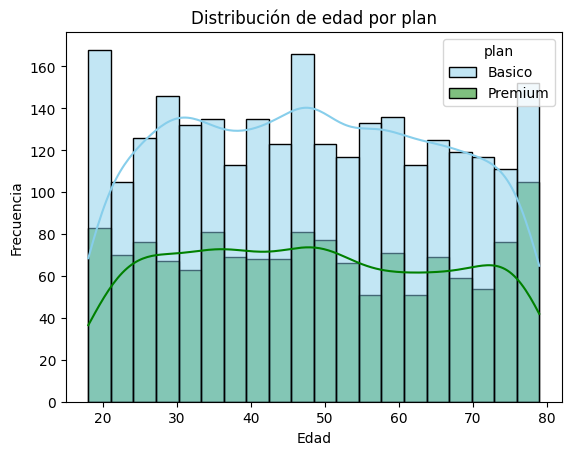

In [37]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan',
             palette=['skyblue', 'green'], bins=20, kde=True)
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Histogramas completos: <code>hue='plan'</code>, paleta indicada, título y etiquetas en ambos ejes.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Como hay casi el doble de clientes Básico, sus barras siempre serán más altas. Para comparar el <b>comportamiento</b>, prueba <code>stat='probability', common_norm=False</code>.
</div>

💡Insights: Las edades se concentran entre los 18 y 79 años, con una distribucion uniforme, en el plan básico se concentra mas cantidad de personas que en el premium, la edad no iferencea de un plan al otro.
- Distribución ...Simetrica

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien: distribución uniforme y la conclusión de que la edad no diferencia los planes.
</div>

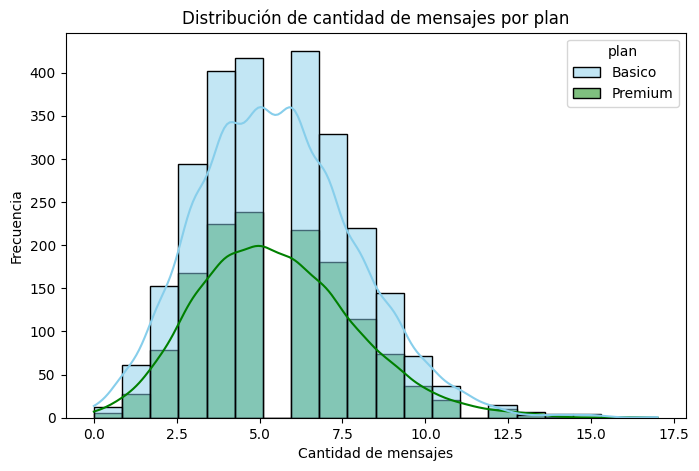

In [38]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan',
             palette=['skyblue', 'green'], bins=20, kde=True)
plt.title('Distribución de cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: La mayoria e usuarios envian mensajes entre 3 y 8, mas centrado en 5. Ambos planes se concentran en los mismos rangos, existen mas usuarios en el plan básico que ene l premium.
- Distribucion simetrica con un ligero sesgo a la derecha.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Insight con rango típico, forma y comparación entre planes. Bien notado que hay más barras de Básico porque hay más clientes.
</div>

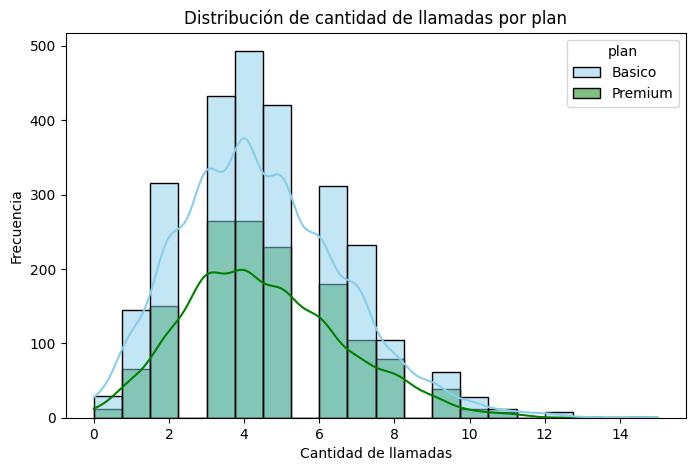

In [42]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan',
             palette=['skyblue', 'green'], bins=20, kde=True)
plt.title('Distribución de cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: los usuarios realizan llamadas entre 2 y 6 llamadas, con un pico alrededor de 4, ambos planes se comportan de manera muy similar.
- Distribución ...Sesgada a la derecha.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Insight correcto: rango, pico y comportamiento similar entre planes.
</div>

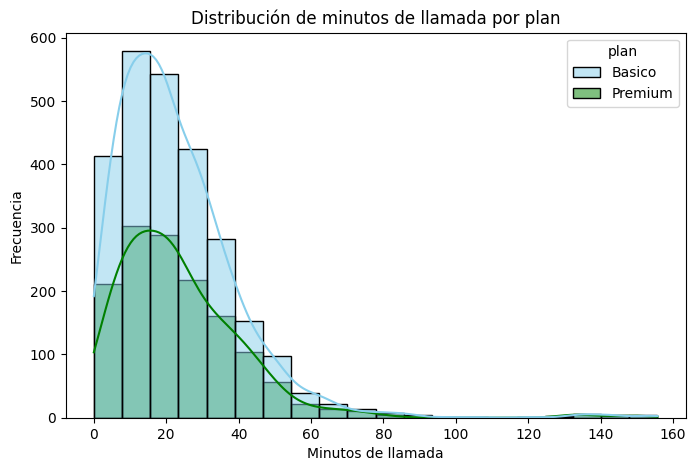

In [43]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan',
             palette=['skyblue', 'green'], bins=20, kde=True)
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: la gran mayoria de usuarios utilizan pocos minutos, entre 10 y 20, existen valores atípicos con valores de 150 minutos. El plan basico sigue concentrando mas usuarios.
- Distribucion con sesgo a la derecha

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el sesgo a la derecha y los valores extremos.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

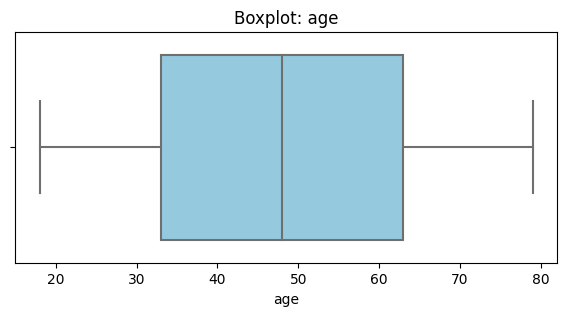

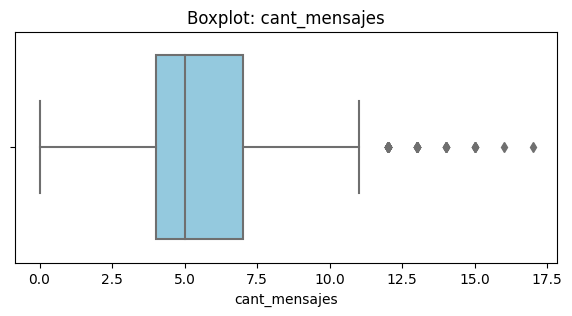

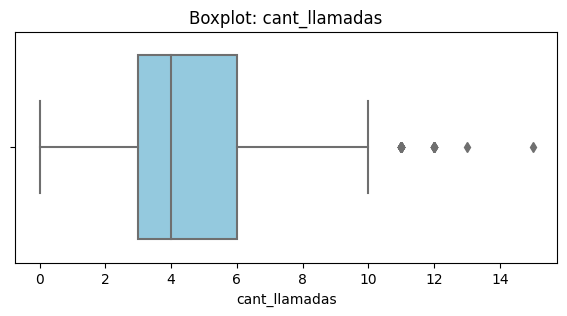

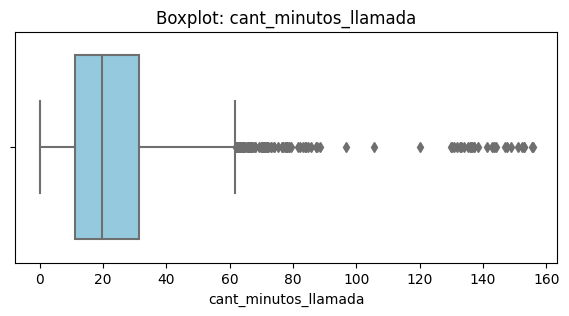

In [45]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Boxplots generados en un bucle con título dinámico. ¡Código limpio!
</div>

💡Insights: 
- Age: ...(presenta o no outliers), No
- cant_mensajes: ...Si, >=12
- cant_llamadas: ...si, >=11
- cant_minutos_llamada: ...Si muchos, >62 y un grupo entre 130-155

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcto: indicas en qué variables hay outliers y desde qué valor.
</div>

In [46]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    n_outliers = (user_profile[col] > limite_superior).sum()
    pct = n_outliers / len(user_profile) * 100

    print(f"{col}")
    print(f"  Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"  Límite superior: {limite_superior:.2f}")
    print(f"  Outliers: {n_outliers} ({pct:.2f}%)\n")


cant_mensajes
  Q1: 4.00 | Q3: 7.00 | IQR: 3.00
  Límite superior: 11.50
  Outliers: 46 (1.15%)

cant_llamadas
  Q1: 3.00 | Q3: 6.00 | IQR: 3.00
  Límite superior: 10.50
  Outliers: 30 (0.75%)

cant_minutos_llamada
  Q1: 11.12 | Q3: 31.41 | IQR: 20.30
  Límite superior: 61.86
  Outliers: 109 (2.73%)



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente! 🌟 Además del límite superior, calculas cuántos clientes lo superan y qué porcentaje representan.
</div>

In [47]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?Son valores que si bien un poco altos, tambien son plausibles(usuarios muy activos), por lo que se deben conservar.
- cant_llamadas: mantener o no outliers, porqué? Mismo caso para "cant_mensajes", deben conservarse
- cant_minutos_llamada: mantener o no outliers, porqué? Tiene muchos outliers (130-155), no son valores imposibles y es muy problabe que esos valores son de usuarios muy intensivos. Aqui puede estar una parte importante del analisis, se sugiere conservar datos y marcarlos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisiones bien argumentadas: los valores son plausibles y representan a los clientes más intensivos. Muy buena idea marcarlos.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [50]:
# Crear columna grupo_uso
user_profile[['cant_mensajes','cant_llamadas','cant_minutos_llamada']] = user_profile[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].fillna(0)
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por uso correcta, y bien que rellenaste con 0 a los clientes sin actividad antes de clasificarlos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>apply(axis=1)</code> recorre fila por fila y es lento con datos grandes. La versión vectorizada es <code>np.select(condiciones, valores, default='Alto uso')</code>.
</div>

In [51]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [52]:
# Crear columna grupo_edad
def clasificar_edad(row):
    if row['age'] < 30 :
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por edad correcta.
</div>

In [53]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

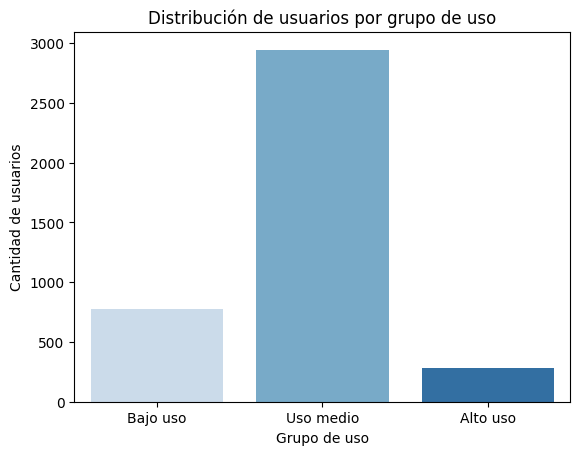

In [54]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'],
              palette='Blues')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot con título, etiquetas y orden lógico de las categorías.
</div>

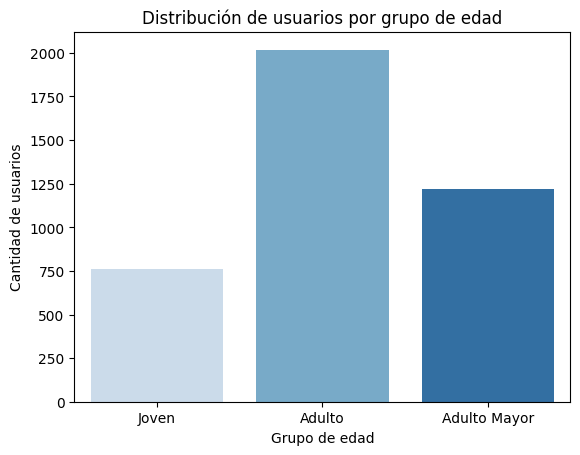

In [55]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad',
              order=['Joven', 'Adulto', 'Adulto Mayor'],
              palette='Blues')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Mismo cuidado en el gráfico por edad. ¡Bien!
</div>

In [56]:
# Cruce edad x uso (para responder cómo se comporta cada edad)
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').mul(100).round(1))

grupo_uso     Alto uso  Bajo uso  Uso medio
grupo_edad                                 
Adulto             7.6      18.1       74.3
Adulto Mayor       6.1      21.0       72.9
Joven              6.7      20.7       72.6


In [57]:
# Porcentajes de cada segmento
print(user_profile['grupo_uso'].value_counts(normalize=True).mul(100).round(1))
print(user_profile['grupo_edad'].value_counts(normalize=True).mul(100).round(1))

Uso medio    73.6
Bajo uso     19.5
Alto uso      7.0
Name: grupo_uso, dtype: float64
Adulto          50.4
Adulto Mayor    30.6
Joven           19.0
Name: grupo_edad, dtype: float64


In [59]:
# Promedio de minutos por segmento
print(user_profile.groupby('grupo_uso')['cant_minutos_llamada'].mean().round(1))
print(user_profile.groupby('grupo_edad')['cant_minutos_llamada'].mean().round(1))

grupo_uso
Alto uso     30.1
Bajo uso     14.9
Uso medio    24.9
Name: cant_minutos_llamada, dtype: float64
grupo_edad
Adulto          23.0
Adulto Mayor    23.6
Joven           23.8
Name: cant_minutos_llamada, dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen trabajo extra! 🌟 El cruce edad × uso, los porcentajes de cada segmento y los minutos promedio respaldan con datos tu análisis ejecutivo.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- age: usaba el centinela -999 en 55 filas (1.4% de 4,000). Distorsionaba la media (33.7 contra 48.1 después de corregir). Se reemplazó con la mediana (48).
- city: tenía 96 filas con "?" (2.4%) y 469 nulos (11.7%), por lo que 565 usuarios (14.1%) no tienen ciudad conocida.
- reg_date: 40 registros con año 2026 (1.0%), imposibles porque los datos llegan hasta 2024. Se eliminaron.
- usage.date: 50 nulos (0.13%).
- duration y length: 55.2% y 44.7% de nulos. Son MAR: duration es nulo en el 99.9% de los mensajes y length en el 99.9% de las llamadas. Es consistente con el negocio (una llamada no tiene longitud de texto ni un mensaje tiene duración), por eso se dejaron como nulos.
- churn_date: 88.4% de nulos (3,534 filas), que corresponden a clientes activos. Se asume que los 466 usuarios restantes (11.7%) abandonaron el servicio.


🔍 **Segmentos por Edad**
-Adultos (30-59): 50.5%, Adultos Mayores (60+): 30.5% y Jóvenes (<30): 19.0%.
-La edad no diferencia el comportamiento: los minutos promedio son casi iguales (23.0, 23.6 y 23.7) y el porcentaje de Uso medio ronda el 73% en los tres grupos.


📊 **Segmentos por Nivel de Uso**
- Uso medio: 73.7%, Bajo uso: 19.3% y Alto uso: 7.0%.
-Minutos promedio: Alto uso 30.2, Uso medio 24.9, Bajo uso 14.9.
-Alto uso por edad: Adultos 7.6%, Jóvenes 6.7%, Adultos Mayores 6.1%. Es una diferencia pequeña.


➡️ Esto sugiere que el nivel de uso, y no la edad, es el segmento útil para decidir ofertas.


💡 **Recomendaciones**
-Alto uso (7%) y outliers de minutos: ofrecer un plan con más minutos o un paquete de excedentes con descuento, porque son los clientes que más consumen.
-Uso medio (73.7%): es la base del negocio. Crear incentivos de migración (bonos de minutos o mensajes) para quienes se acercan a 10 llamadas o 10 mensajes.
-Bajo uso (19.3%): hacer campañas de activación o un plan básico más económico, porque tienen mayor riesgo de cancelar al no percibir valor.
-Segmentar por nivel de uso, no por edad. La edad puede servir solo para el canal de comunicación.
-Revisar el diseño de planes: el uso es muy bajo frente a lo incluido (Básico: 100 min; Premium: 600 min). El promedio de minutos es 23 y el máximo 155. Un plan intermedio o más barato podría capturar a quienes hoy pagan por capacidad que no usan.
-Calidad de datos: exigir ciudad en el registro y eliminar el centinela -999 desde el origen.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Análisis ejecutivo de gran nivel! 🌟 Cuantificas cada problema de datos, das el tamaño y el consumo de cada segmento, demuestras con datos que la edad no diferencia el comportamiento y propones recomendaciones concretas para cada nivel de uso, incluida la calidad de datos en el origen.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al corregir la limpieza, actualiza el texto: la mediana de <code>age</code> será 48, los registros de 2026 se marcarán como nulos (no se eliminan) y los porcentajes de los segmentos podrían variar ligeramente. Borra también los puntos suspensivos de la plantilla ("Esto sugiere que ...").<br>
En la última recomendación, ten en cuenta que los minutos incluidos en los planes son <b>mensuales</b>, mientras que <code>cant_minutos</code> es el total de todo el periodo.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El link quedó en dos celdas de <b>código</b> (abajo): al ejecutar todo el notebook producen un <code>SyntaxError</code>. Escríbelo en esta celda Markdown, en lugar de <code>`LINK a tu repo aquí`</code>, y elimina las celdas de código. Verifica también que el repositorio tenga el notebook y un <code>README.md</code>.
</div>

In [46]:
https://github.com/juanmartinsahagunflores-max/sprint7-final-project.git

SyntaxError: invalid syntax (3246999688.py, line 1)

In [ ]:
https://github.com/juanmartinsahagunflores-max/sprint7-final-project

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>✅</td></tr><tr><td></td><td>Fechas (errors='coerce', .dt.year)</td><td>✅</td></tr><tr><td></td><td>Diagnósticos escritos</td><td>🟡 2022-2023 no son años imposibles</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>🟡 mediana con el sentinel</td></tr><tr><td></td><td>"?" → pd.NA</td><td>🟡 salida inconsistente (Restart &amp; Run All)</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>❌ se eliminaron 40 filas</td></tr><tr><td></td><td>Evaluación MAR y decisión</td><td>✅</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅</td></tr><tr><td></td><td>Revisión estadística</td><td>✅</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas con hue</td><td>✅</td></tr><tr><td></td><td>Interpretación</td><td>✅</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Problemas, segmentos y recomendaciones</td><td>✅</td></tr><tr><td>8. Publicación</td><td>Link al repositorio</td><td>🟡 en celdas de código</td></tr></table><br>Criterios en ❌ → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Juan, tu proyecto es de muy buen nivel y está a un paso de la aprobación. Para la siguiente iteración, el único punto bloqueante ❌ es:
<ol><li><b>Paso 3.1:</b> marcar como nulas las fechas de 2026 en lugar de eliminar las filas.</li></ol>
En la siguiente iteración revisaré únicamente este punto, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente calcular la mediana sin el sentinel, hacer <b>Restart &amp; Run All</b> para que las salidas coincidan con tu código, y actualizar el análisis ejecutivo con las cifras corregidas.<br><br>
¡Ánimo, ya casi está! 💪
</div>